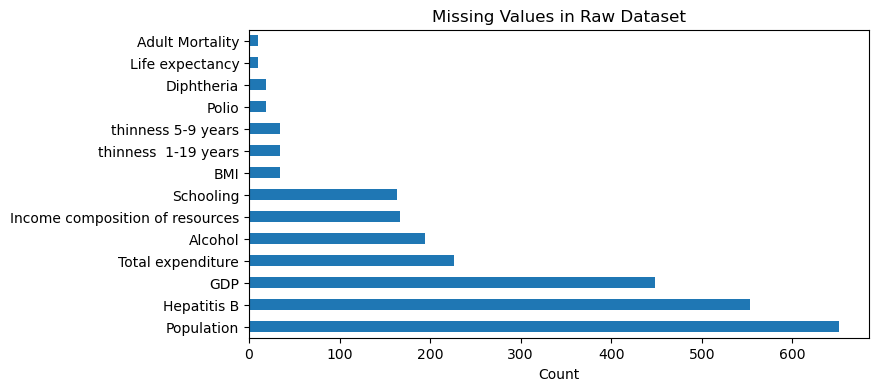

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor

raw_df = pd.read_csv("../data/raw/Life Expectancy Data.csv")
raw_df.columns = raw_df.columns.str.strip()

# Top columns with missing Values
missing = raw_df.isnull().sum()
missing[missing > 0].sort_values(ascending=False).plot(kind="barh", figsize=(8, 4), title="Missing Values in Raw Dataset")
plt.xlabel("Count")
plt.show()

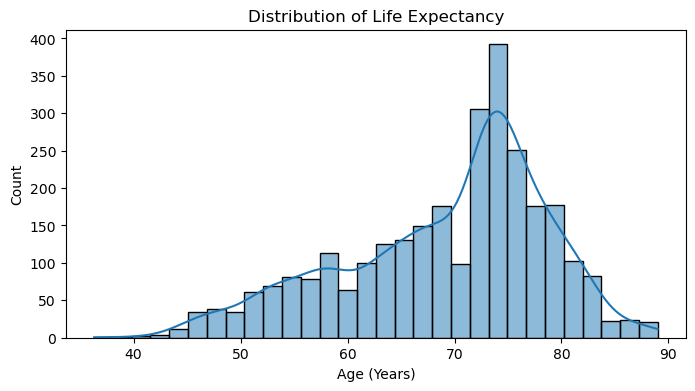

In [2]:
clean_df = pd.read_csv("../data/processed/cleaned_life_expectancy.csv")

plt.figure(figsize=(8, 4))
sns.histplot(clean_df["Life expectancy"], bins=30, kde=True)
plt.title("Distribution of Life Expectancy")
plt.xlabel("Age (Years)")
plt.show()

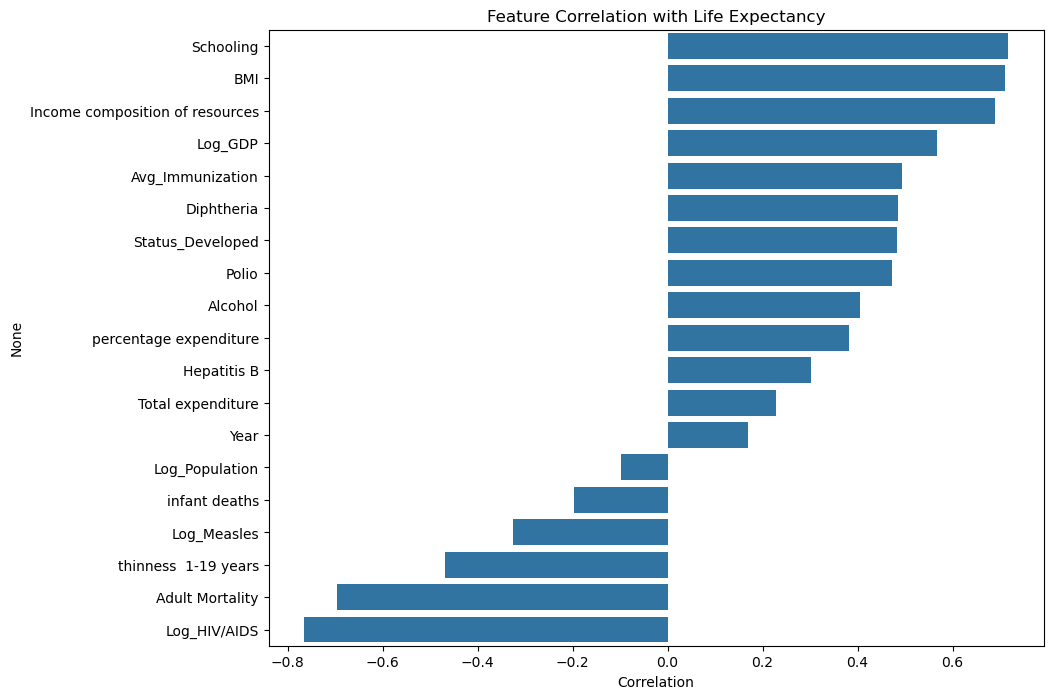

In [3]:
plt.figure(figsize=(10, 8))
corr = clean_df.corr()["Life expectancy"].sort_values(ascending=False)
sns.barplot(x=corr.values[1:], y=corr.index[1:])
plt.title("Feature Correlation with Life Expectancy")
plt.xlabel("Correlation")
plt.show()

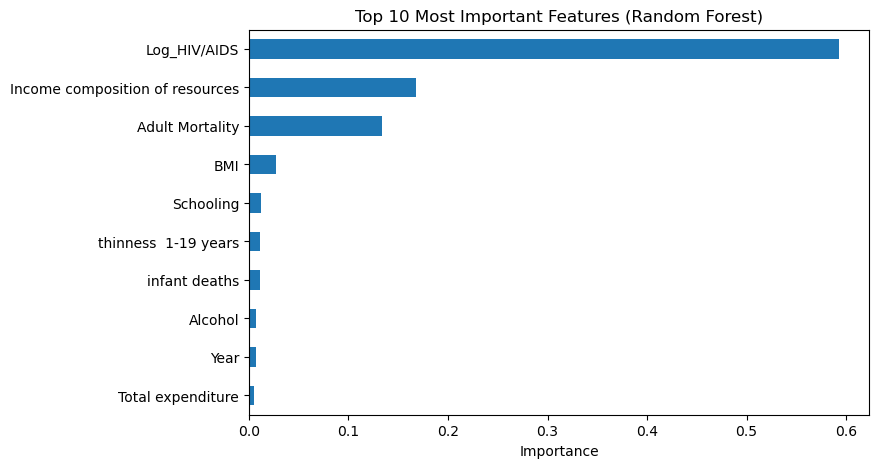

In [4]:
X = clean_df.drop(columns=["Life expectancy"])
y = clean_df["Life expectancy"]

rf = RandomForestRegressor(n_estimators=200, random_state=42)
rf.fit(X, y)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
importances.plot(kind="barh", figsize=(8, 5), title="Top 10 Most Important Features (Random Forest)")
plt.gca().invert_yaxis()
plt.xlabel("Importance")
plt.show()